In [1]:
!pip3 install scanpy==1.9.3

In [2]:
!pip3 install scib-metrics==0.5.1 #bug in version from requirements

In [3]:
!pip3 install leidenalg==0.10.1

In [4]:
!pip3 install louvain==0.8.1

## Imports

In [5]:
import scanpy as sc
import numpy as np
import pandas as pd
import metrics_lib as metrics
import os

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2024-04-05 01:58:34.328353: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9373] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-05 01:58:34.328439: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-05 01:58:34.329952: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1534] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## Set global variables

In [6]:
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Data'))
RESULT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results'))

In [7]:
#set variables to subset data
dataset="Santamaria"
condition="C"
mode="sample"

## load and prep Data

### load and prep embedding 

In [8]:
adata = sc.read_h5ad(f"{DATA_DIR}/Mapping/Santamaria_mapped_emb_subsetted_and_processed.h5ad")

In [9]:
adata[adata.obs.dataset==dataset].obs["sample"]

AS_AS_ENTIRE-1-13-S1_AAACCCAAGAAGTGTT-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGACAGCGT-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAGCAGAA-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGAGGGTAA-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
AS_AS_ENTIRE-1-13-S1_AAACCCAAGGCCTTCG-1            run_count_0038_AS0-21D0013_ENTIRE-1-13-S1
                                                                    ...                     
Estonia_EST-41-G2-EPST109_TTTGGAGTCGACATTG-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGGTTGTTATGTCG-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGTTGAGGGTAGCT-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGTTGTCCATTCAT-1    run_count_0192_ASH-21G0011_EST-41-G2-EPST109
Estonia_EST-41-G2-EPST109_TTTGTTGTCGGACTGC-1    run_count_0192_ASH-21G

In [10]:
#correct endometrial pathology for group=WOI Control as they are control
adata[adata.obs.dataset=="Santamaria"].obs['Group']
adata.obs.loc[adata.obs.Group=="WOI Control",'Endometrial_pathology']="C"

In [11]:
# make X to obsm
adata.obsm["X_scanvi"] = adata.X

In [12]:
#subset to dataset
adata=adata[(adata.obs.dataset == dataset )|(adata.obs['ref_or_query']=="ref") ].copy()

In [13]:
#subset to condition
adata=adata[(adata.obs['Endometrial_pathology']== condition )|(adata.obs['ref_or_query']=="ref") ].copy()

In [14]:
adata.obs.dataset

HCA_A_RepT_RNA13247830_AAACCTGAGCGATGAC-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGAGCTAGGCA-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGCACCAACCG-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGCACCTGGTG-Mareckova     Mareckova
HCA_A_RepT_RNA13247830_AAACCTGCATAGAAAC-Mareckova     Mareckova
                                                        ...    
Estonia_EST-41-G2-EPST109_TTTGGAGTCGACATTG-1         Santamaria
Estonia_EST-41-G2-EPST109_TTTGGTTGTTATGTCG-1         Santamaria
Estonia_EST-41-G2-EPST109_TTTGTTGAGGGTAGCT-1         Santamaria
Estonia_EST-41-G2-EPST109_TTTGTTGTCCATTCAT-1         Santamaria
Estonia_EST-41-G2-EPST109_TTTGTTGTCGGACTGC-1         Santamaria
Name: dataset, Length: 187399, dtype: category
Categories (7, object): ['GarciaAlonso', 'Huang', 'Lai', 'Mareckova', 'Santamaria', 'Tan', 'Wang']

### improvise on subject ID (Specific to this dataset)

Since we don't have an explicit subject_id, 
we improvise by combining three features age, genotype and group to hopefully get the individual donors. We have 33 particpants in HECA and 6 controls in Santamaria + 9 patients in Santamaria

In [213]:
donors = adata.obs.groupby(["dataset","Age","genotype","Group"]).agg({"sample":"nunique"}).reset_index()
donors.loc[(donors["sample"]>0)]

,dataset,Age,genotype,Group,sample
232,GarciaAlonso,23,A30,Ctrl_whole_uterus,2
477,GarciaAlonso,26,E2,Ctrl_Superficial,2
480,GarciaAlonso,26,E3,Ctrl_Superficial,2
588,GarciaAlonso,29,E1,Ctrl_Superficial,2
1141,GarciaAlonso,35,A13,Ctrl_whole_uterus,2
2334,Huang,24,GSM6605440,Ctrl_Superficial,1
2553,Huang,29,GSM6605437,Ctrl_Superficial,1
2898,Huang,32,GSM6605438,Ctrl_Superficial,1
3015,Huang,33,GSM6605439,Ctrl_Superficial,1
5736,Lai,nan,GSM5572238,Ctrl_Superficial,1


In [214]:
len(donors.loc[(donors["sample"]>0)])

32

We don't seem to find one donor from the HECA atlas. The samples from Santameria are all from differnet donors, so we set HECA donors to the one we found and Santamaria donors to just the samples. If additional information is availible, we can recalculate the metric.

In [215]:
adata.obs["donor_id"]=np.nan

In [216]:
for i,d in enumerate(donors.iterrows()) :
    adata.obs.loc[(adata.obs.dataset==d[1]["dataset"])&
                  (adata.obs.Age==d[1]["Age"])&
                  (adata.obs.genotype==d[1]["genotype"])&
                 (adata.obs.Group==d[1]["Group"]),"donor_id"]=f'subject_{i}'

In [217]:
for i,d in enumerate(adata[adata.obs.dataset==dataset].obs["sample"].cat.categories):
    adata.obs.loc[(adata.obs["sample"]==d,"donor_id")]=f'query_subject_{i}'


### load and prep query_counts

In [218]:
adata_query=sc.read_h5ad(f"{DATA_DIR}/Query_counts/Asherman_syndrome_wo_wang.h5ad")

In [219]:
adata_query

AnnData object with n_obs × n_vars = 59301 × 33538
    obs: 'sample', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'Group', 'phase', 'menstrual_cycle_day', 'principal_cell_types', 'celltype', 'dataset', 'Endometrial_pathology'
    var: 'features'

In [220]:
#subset to only query of interest (dataset and condition)
adata_query =  adata_query[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [221]:
adata_query.obs = adata.obs.loc[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))]

In [223]:
adata_query

AnnData object with n_obs × n_vars = 18965 × 33538
    obs: 'n_genes', 'sample', 'library', 'Processing', 'Treatment', '10x kit', 'percent_mito', 'n_counts', 'scrublet_score', 'genotype', 'Library_genotype', 'Group', 'Endometriosis_stage', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Biopsy_type', 'Tissue_sampled', 'Age', 'Endometrial_pathology', 'celltype', 'lineage', 'label_long', '_scvi_batch', '_scvi_labels', 'nCount_RNA', 'nFeature_RNA', 'mitochondria_ratio', 'menstrual_cycle_day', 'principal_cell_types', 'batch', 'ref_or_query', 'leiden', 'donor_id'
    var: 'features'
    obsm: 'X_scanvi'

In [222]:
#set obsm layer X_scanvi to embedding
adata_query.obsm["X_scanvi"] = adata[list(set(adata_query.obs.index).intersection(set(adata.obs.index)))].X

## run metrics

In [224]:
#set some variables for running metrics
obsm_emb_key = 'X_scanvi'
donor_key= 'donor_id'
dataset_key="dataset"
sample_key="sample"
original_emb_key=None
batch_key = "sample"

In [225]:
scib_results = metrics.calculate_scib_metrics(adata, obsm_emb_key, batch_key, dataset_key, sample_key, dry_run=False)

Time to complete scib neighbors calculation: 124.807 s
Time to complete lisi_batch: 2.222 s
Time to complete kbet_batch: 0.415 s


In [226]:
symphony_results = metrics.calculate_symphony_metrics(adata, adata_query, obsm_emb_key, donor_key, dataset_key, sample_key, dry_run=False)

Time to complete symphony metrics neighbors calculation: 2.091 s
Time to complete lisi_query_donor: 0.946 s
Time to complete wiq_knn_corr: 110.362 s


In [227]:
other_results = metrics.calculate_other_metrics(adata, adata_query, obsm_emb_key, dataset_key, sample_key, dry_run=False)

/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: divide by zero encountered in log
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell
/dss/dsshome1/0F/di35qon/Metrics/Code/metrics_lib.py:188: RuntimeWarning: invalid value encountered in multiply
  return np.nansum(px * np.log(px), axis=1)  # calculate label entropy for each cell


Time to complete cluster_preservation_score: 93.787 s


In [228]:
#save results
adata.obs["lisi_batch"] = scib_results["lisi_batch"]["per_cell"]
adata.obs["kbet_batch"] = scib_results["kbet_batch"]["per_cell"]
adata.obs['lisi_query_donor'] = symphony_results['lisi_query_donor']["per_cell"]
adata.obs['wiq_knn_corr'] = symphony_results['wiq_knn_corr']["per_cell"]
adata.obs['cluster_preservation_score']=other_results['cluster_preservation_score']["per_cell"]

In [229]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].dropna()

,lisi_batch,kbet_batch,lisi_query_donor,wiq_knn_corr,cluster_preservation_score
Estonia_EST-21-G2-EPST65_AAACCCACATATCTGG-1,0.078938,0.0,0.423742,0.083615,0.0
Estonia_EST-21-G2-EPST65_AAACCCAGTCCGCAGT-1,0.130820,0.0,0.333745,0.052648,0.0
Estonia_EST-21-G2-EPST65_AAACCCATCAGTGATC-1,0.038777,0.0,0.152788,0.009007,0.0
Estonia_EST-21-G2-EPST65_AAACCCATCTCCTACG-1,0.058061,0.0,0.229341,-0.017872,0.0
Estonia_EST-21-G2-EPST65_AAACGAACACGCGCTA-1,0.030548,0.0,0.452690,0.030851,0.0
...,...,...,...,...,...
Estonia_EST-41-G2-EPST109_TTTGGAGTCGACATTG-1,0.026689,0.0,0.420724,-0.067116,0.0
Estonia_EST-41-G2-EPST109_TTTGGTTGTTATGTCG-1,0.012254,0.0,0.334233,-0.040095,0.0
Estonia_EST-41-G2-EPST109_TTTGTTGAGGGTAGCT-1,0.002093,0.0,0.543642,-0.017356,0.0
Estonia_EST-41-G2-EPST109_TTTGTTGTCCATTCAT-1,0.055056,0.0,0.305037,0.008222,0.0


In [230]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']].to_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv')

## Visualize 

Run Load and prep embeddings and set global variables first

In [15]:
adata.obs[["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']] = pd.read_csv(f'{RESULT_DIR}/metrics_{mode}_{dataset}_{condition}.csv',index_col = "Unnamed: 0")

In [16]:
sc.pp.neighbors(adata,n_neighbors=50)

In [17]:
sc.tl.umap(adata)

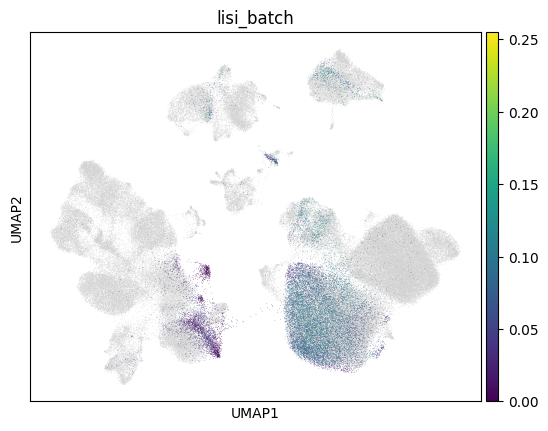

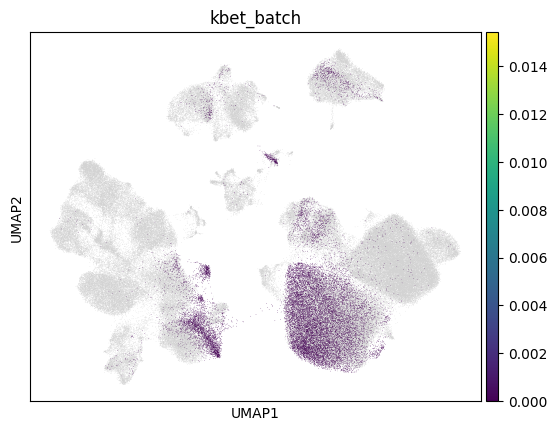

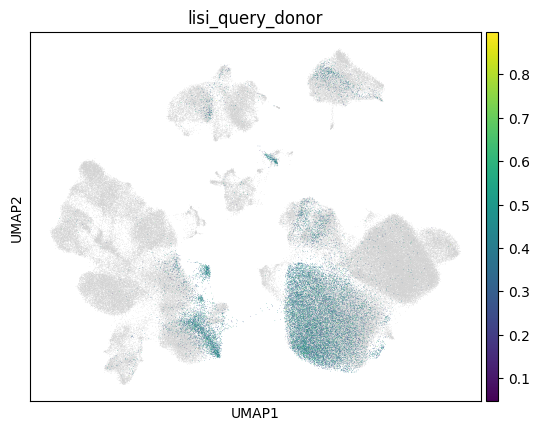

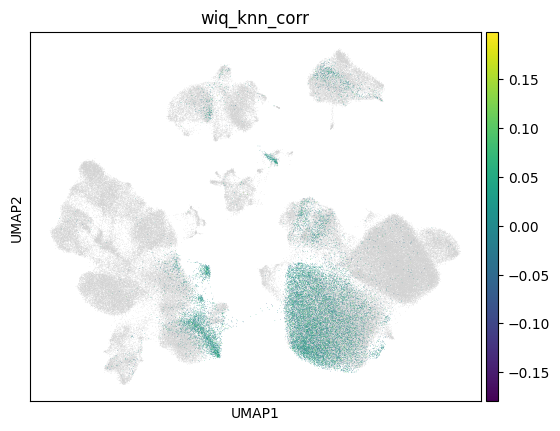

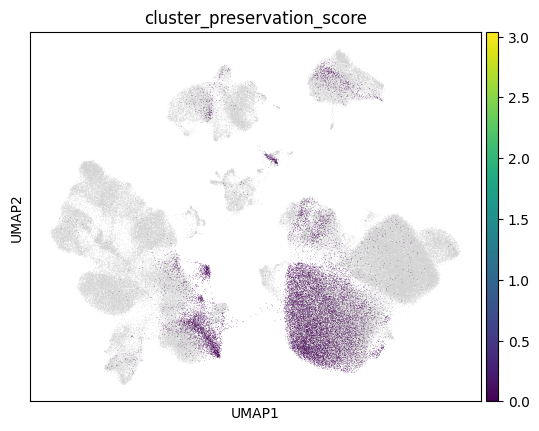

In [19]:
for metric in ["lisi_batch","kbet_batch",'lisi_query_donor','wiq_knn_corr','cluster_preservation_score']:
    adata.obs.loc[adata.obs['ref_or_query']=="ref",metric]=np.nan
    sc.pl.umap(adata,color=metric)